<a href="https://colab.research.google.com/github/muzaneltinay-ui/iot-temperature-analysis/blob/main/iot_temperature_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Understanding the data

In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
df = pd.read_csv("iot_telemetry_data.csv")
df.head()

,id,room_id/id,noted_date,temp,out/in
0,__export__.temp_log_196134_bd201015,Room Admin,08-12-2018 09:30,29,In
1,__export__.temp_log_196131_7bca51bc,Room Admin,08-12-2018 09:30,29,In
2,__export__.temp_log_196127_522915e3,Room Admin,08-12-2018 09:29,41,Out
3,__export__.temp_log_196128_be0919cf,Room Admin,08-12-2018 09:29,41,Out
4,__export__.temp_log_196126_d30b72fb,Room Admin,08-12-2018 09:29,31,In


In [ ]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97606 entries, 0 to 97605
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   id          97606 non-null  object
 1   room_id/id  97606 non-null  object
 2   noted_date  97606 non-null  object
 3   temp        97606 non-null  int64 
 4   out/in      97606 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.7+ MB


In [ ]:
df["noted_date"] = pd.to_datetime(df["noted_date"], format="%d-%m-%Y %H:%M")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97606 entries, 0 to 97605
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   id          97606 non-null  object        
 1   room_id/id  97606 non-null  object        
 2   noted_date  97606 non-null  datetime64[ns]
 3   temp        97606 non-null  int64         
 4   out/in      97606 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(3)
memory usage: 3.7+ MB


In [ ]:
df["noted_date"].min()

Timestamp('2018-07-28 07:06:00')

In [ ]:
df["temp"].describe()
df["out/in"].value_counts()

,count
out/in,
Out,77261
In,20345


In [ ]:
df["noted_date"].max()

Timestamp('2018-12-08 09:30:00')

In [ ]:
df["temp"].describe()

,temp
count,97606.000000
mean,35.053931
std,5.699825
min,21.000000
25%,30.000000
50%,35.000000
75%,40.000000
max,51.000000


In [ ]:
print(df.groupby("out/in")["temp"].describe())

          count       mean       std   min   25%   50%   75%   max
out/in                                                            
In      20345.0  30.453920  2.238101  21.0  29.0  31.0  32.0  41.0
Out     77261.0  36.265244  5.717055  24.0  31.0  37.0  40.0  51.0


In [ ]:
print(df["noted_date"].max() - df["noted_date"].min())

133 days 02:24:00


In [ ]:
df["hour"] = df["noted_date"].dt.hour
print(df.groupby(["hour", "out/in"])["temp"].mean())
df["noted_date"].min()


hour  out/in
0     In        29.040541
      Out       35.098123
1     In        30.482587
      Out       35.135115
2     In        30.844011
      Out       34.543115
3     In        29.337079
      Out       35.389824
4     In        29.472141
      Out       37.528386
5     In        29.912500
      Out       39.230662
6     In        30.589610
      Out       39.677053
7     In        30.914230
      Out       38.195230
8     In        30.700632
      Out       38.416396
9     In        30.606692
      Out       38.317177
10    In        30.736909
      Out       37.438360
11    In        30.353682
      Out       36.931439
12    In        31.308743
      Out       37.158198
13    In        30.887597
      Out       36.824096
14    In        30.979134
      Out       36.389654
15    In        30.247209
      Out       36.826597
16    In        30.423540
      Out       35.481833
17    In        30.189227
      Out       36.247749
18    In        29.713542
      Out       35.346004

Timestamp('2018-07-28 07:06:00')

In [ ]:
df["noted_date"].min()

Timestamp('2018-07-28 07:06:00')

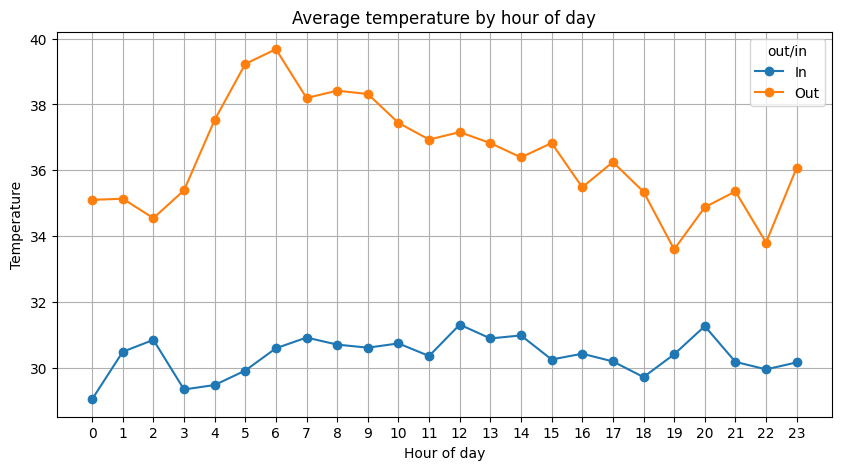

In [ ]:
import matplotlib.pyplot as plt

df["hour"] = df["noted_date"].dt.hour

hourly = df.groupby(["hour", "out/in"])["temp"].mean().unstack()

hourly.plot(marker="o", figsize=(10, 5))
plt.title("Average temperature by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Temperature")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

In [ ]:
print(df.groupby(["hour", "out/in"]).size().unstack())

out/in    In   Out
hour              
0        518  2823
1        402  2731
2        718  2876
3        890  2791
4        682  2008
5        880  3594
6        770  2375
7       1026  2264
8       1266  1537
9       1584  2806
10      1566  3561
11      1032  2640
12      1098  2952
13       774  3843
14      1294  5954
15      1254  4775
16      1164  3578
17       724  3221
18       576  3604
19       486  4513
20       583  3577
21       381  3141
22       343  3464
23       334  2633


In [ ]:
print(df["noted_date"].max() - df["noted_date"].min())

133 days 02:24:00


In [ ]:
df.shape

(97606, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 97606 entries, 0 to 97605
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   id          97606 non-null  object        
 1   room_id/id  97606 non-null  object        
 2   noted_date  97606 non-null  datetime64[ns]
 3   temp        97606 non-null  int64         
 4   out/in      97606 non-null  object        
 5   hour        97606 non-null  int32         
dtypes: datetime64[ns](1), int32(1), int64(1), object(3)
memory usage: 4.1+ MB


In [ ]:
import matplotlib as plt

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df.isnull().sum()

,0
id,0
room_id/id,0
noted_date,0
temp,0
out/in,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
import os
print(os.listdir("."))

['.config', 'iot_telemetry_data.csv.csv', 'sample_data']


In [ ]:
['.config', 'sample_data', 'iot_telemetry_data.csv.csv']

['.config', 'sample_data', 'iot_telemetry_data.csv.csv']

In [ ]:
df = pd.read_csv("iot_telemetry_data.csv")


In [ ]:
import os
print(os.listdir("."))

['.config', '.ipynb_checkpoints', 'iot_telemetry_data.csv', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv("iot_telemetry_data.csv")
df["noted_date"] = pd.to_datetime(df["noted_date"], format="%d-%m-%Y %H:%M")
df["hour"] = df["noted_date"].dt.hour
df["date"] = df["noted_date"].dt.date

print(df["date"].nunique())

daily6 = df[df["hour"] == 6].groupby(["date", "out/in"])["temp"].mean().unstack()
print(daily6.describe())

86
out/in         In        Out
count   42.000000  58.000000
mean    30.076317  42.686721
std      1.882840   4.315519
min     24.250000  31.750000
25%     29.068182  40.240530
50%     30.221739  43.355615
75%     31.000000  45.650000
max     34.000000  48.642857


In [ ]:
df["month"] = df["noted_date"].dt.month
print(df.groupby(["month", "out/in"])["temp"].mean().unstack())
print(df.groupby("month")["date"].nunique())

out/in         In        Out
month                       
7       31.125000  31.888889
8       29.942907  31.157604
9       30.671172  31.223356
10      31.528517  39.870501
11      30.429499  40.177580
12      28.401540  37.327955
month
7      3
8      9
9     26
10    21
11    19
12     8
Name: date, dtype: int64


NameError: name 'plt' is not defined

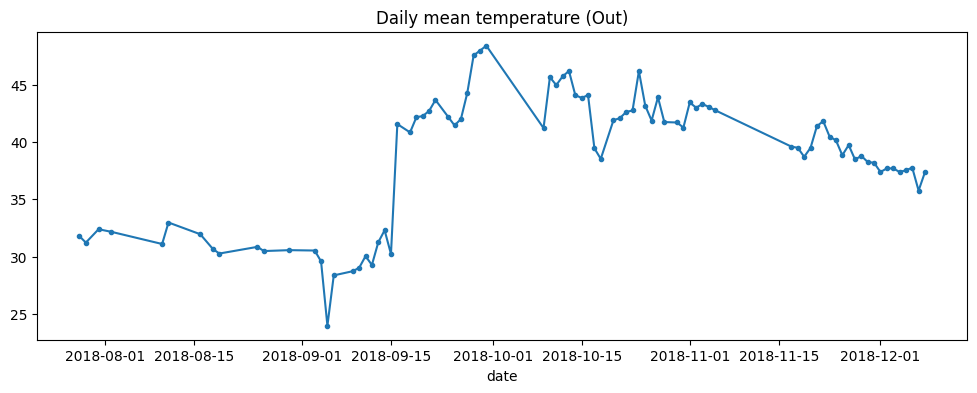

In [ ]:
daily = df[df["out/in"] == "Out"].groupby("date")["temp"].mean()
daily.plot(marker=".", figsize=(12, 4), title="Daily mean temperature (Out)")
plt.ylabel("Temperature")
plt.show()

In [ ]:
daily = df[df["out/in"] == "Out"].groupby("date")["temp"].mean()
print(daily.diff().idxmax(), daily.diff().max())

2018-09-16 11.314176245210728


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("iot_telemetry_data.csv")
df["noted_date"] = pd.to_datetime(df["noted_date"], format="%d-%m-%Y %H:%M")
df = df.drop_duplicates()
df = df.drop(columns=["room_id/id"])
df = df.rename(columns={"out/in": "location"})
df["date"] = df["noted_date"].dt.date

In [4]:
daily_out = df[df["location"] == "Out"].groupby("date")["temp"].mean()
daily_out.index = pd.to_datetime(daily_out.index)

check = pd.DataFrame({
    "temp": daily_out,
    "change": daily_out.diff(),
    "days_since_prev": daily_out.index.to_series().diff().dt.days,
})

print(check.sort_values("change", ascending=False).head(10))

                 temp     change  days_since_prev
date                                             
2018-09-16  41.555556  11.314176              1.0
2018-10-10  45.640719   4.433211              1.0
2018-09-06  28.382594   4.382594              1.0
2018-10-24  46.160714   3.419237              1.0
2018-10-20  41.891256   3.366361              2.0
2018-09-28  47.529126   3.273972              1.0
2018-09-27  44.255155   2.266266              1.0
2018-11-01  43.433604   2.185217              1.0
2018-10-27  43.887097   2.025783              1.0
2018-09-13  31.261084   1.973513              1.0


In [5]:
mask = (df["location"] == "Out") & (df["noted_date"] >= "2018-09-15") & (df["noted_date"] < "2018-09-17")
around = df[mask]

print(around.groupby([around["noted_date"].dt.date, around["noted_date"].dt.hour])["temp"].agg(["mean", "count"]))

                            mean  count
noted_date noted_date                  
2018-09-15 12          34.000000      1
           15          31.000000      2
           18          30.333333      9
           19          30.000000     13
           20          29.500000      4
2018-09-16 14          40.692308     13
           15          42.000000     17
           16          41.916667     12
           17          41.333333      3


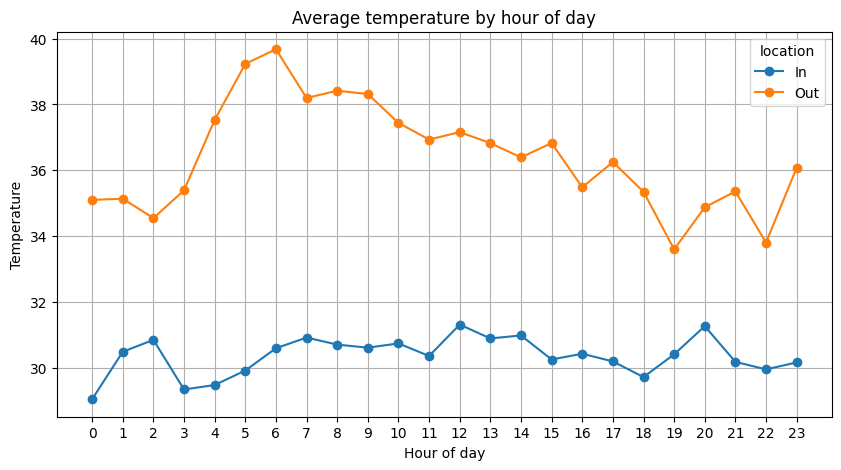

In [12]:
import matplotlib.pyplot as plt

df["hour"] = df["noted_date"].dt.hour

hourly = df.groupby(["hour", "location"])["temp"].mean().unstack()

hourly.plot(marker="o", figsize=(10, 5))
plt.title("Average temperature by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Temperature")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

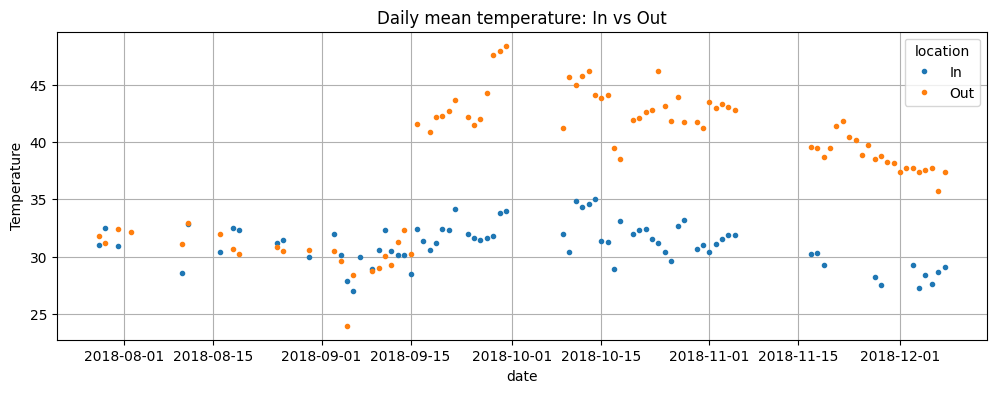

In [13]:
import matplotlib.pyplot as plt

daily = df.groupby(["date", "location"])["temp"].mean().unstack()

daily.plot(style=".", figsize=(12, 4), title="Daily mean temperature: In vs Out")
plt.ylabel("Temperature")
plt.grid(True)
plt.show()

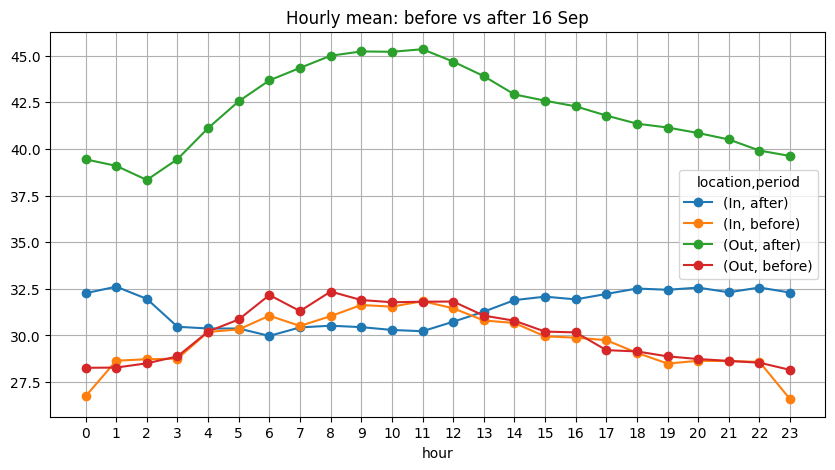

location  period
In        after     51
          before    23
Out       after     61
          before    23
Name: date, dtype: int64


In [6]:
df["hour"] = df["noted_date"].dt.hour
df["period"] = (df["noted_date"] >= "2018-09-16").map({False: "before", True: "after"})

hourly = (
    df.groupby(["location", "period", "date", "hour"])["temp"].mean()
      .groupby(["location", "period", "hour"]).mean()
      .unstack(["location", "period"])
)

hourly.plot(marker="o", figsize=(10, 5), title="Hourly mean: before vs after 16 Sep")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

print(df.groupby(["location", "period"])["date"].nunique())